# Парадокс Симпсона на данных Palmer Penguins

По всем пингвинам вместе длина и высота клюва связаны отрицательно, а внутри каждого вида — положительно. Ноутбук считает корреляции Пирсона и строит два графика для сравнения.

Данные: датасет Palmer Penguins. Если CSV-файла рядом нет, он загружается из пакета `palmerpenguins`.

In [1]:
# ===== 0. Загрузка данных =====
!pip install palmerpenguins -q

import json, re, os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

NB_PATH = '/kaggle/pinguins.ipynb'

# Ищем CSV: стандартная папка Kaggle и путь, указанный в исходном ноутбуке (если ноутбук есть)
candidates = ['/kaggle/input/penguins/penguins.csv']
if os.path.exists(NB_PATH):
    with open(NB_PATH, encoding='utf-8') as f:
        nb = json.load(f)
    code = '\n'.join(''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code')
    m = re.search(r"read_csv\(\s*['\"](.+?)['\"]", code)
    if m:
        print('В ноутбуке данные читаются из:', m.group(1))
        candidates.append(os.path.normpath(os.path.join(os.path.dirname(NB_PATH), m.group(1))))

csv_path = next((p for p in candidates if os.path.exists(p)), None)

if csv_path:
    df = pd.read_csv(csv_path)
    print('Загружено из', csv_path)
else:
    from palmerpenguins import load_penguins
    df = load_penguins()
    print('CSV не найден, загружен тот же датасет из пакета palmerpenguins')

df = df.dropna(subset=['bill_length_mm', 'bill_depth_mm'])

CSV не найден, загружен тот же датасет из пакета palmerpenguins


In [2]:
# ===== 1. Корреляции: все вместе и по видам =====
rows = []
r, p = stats.pearsonr(df['bill_length_mm'], df['bill_depth_mm'])
rows.append({'группа': 'все вместе', 'n': len(df), 'r': round(r, 3), 'p-value': f'{p:.1e}'})
for sp, g in df.groupby('species'):
    r, p = stats.pearsonr(g['bill_length_mm'], g['bill_depth_mm'])
    rows.append({'группа': sp, 'n': len(g), 'r': round(r, 3), 'p-value': f'{p:.1e}'})
print(pd.DataFrame(rows).to_string(index=False))

    группа   n      r p-value
все вместе 342 -0.235 1.1e-05
    Adelie 151  0.391 6.7e-07
 Chinstrap  68  0.654 1.5e-09
    Gentoo 123  0.643 1.0e-15


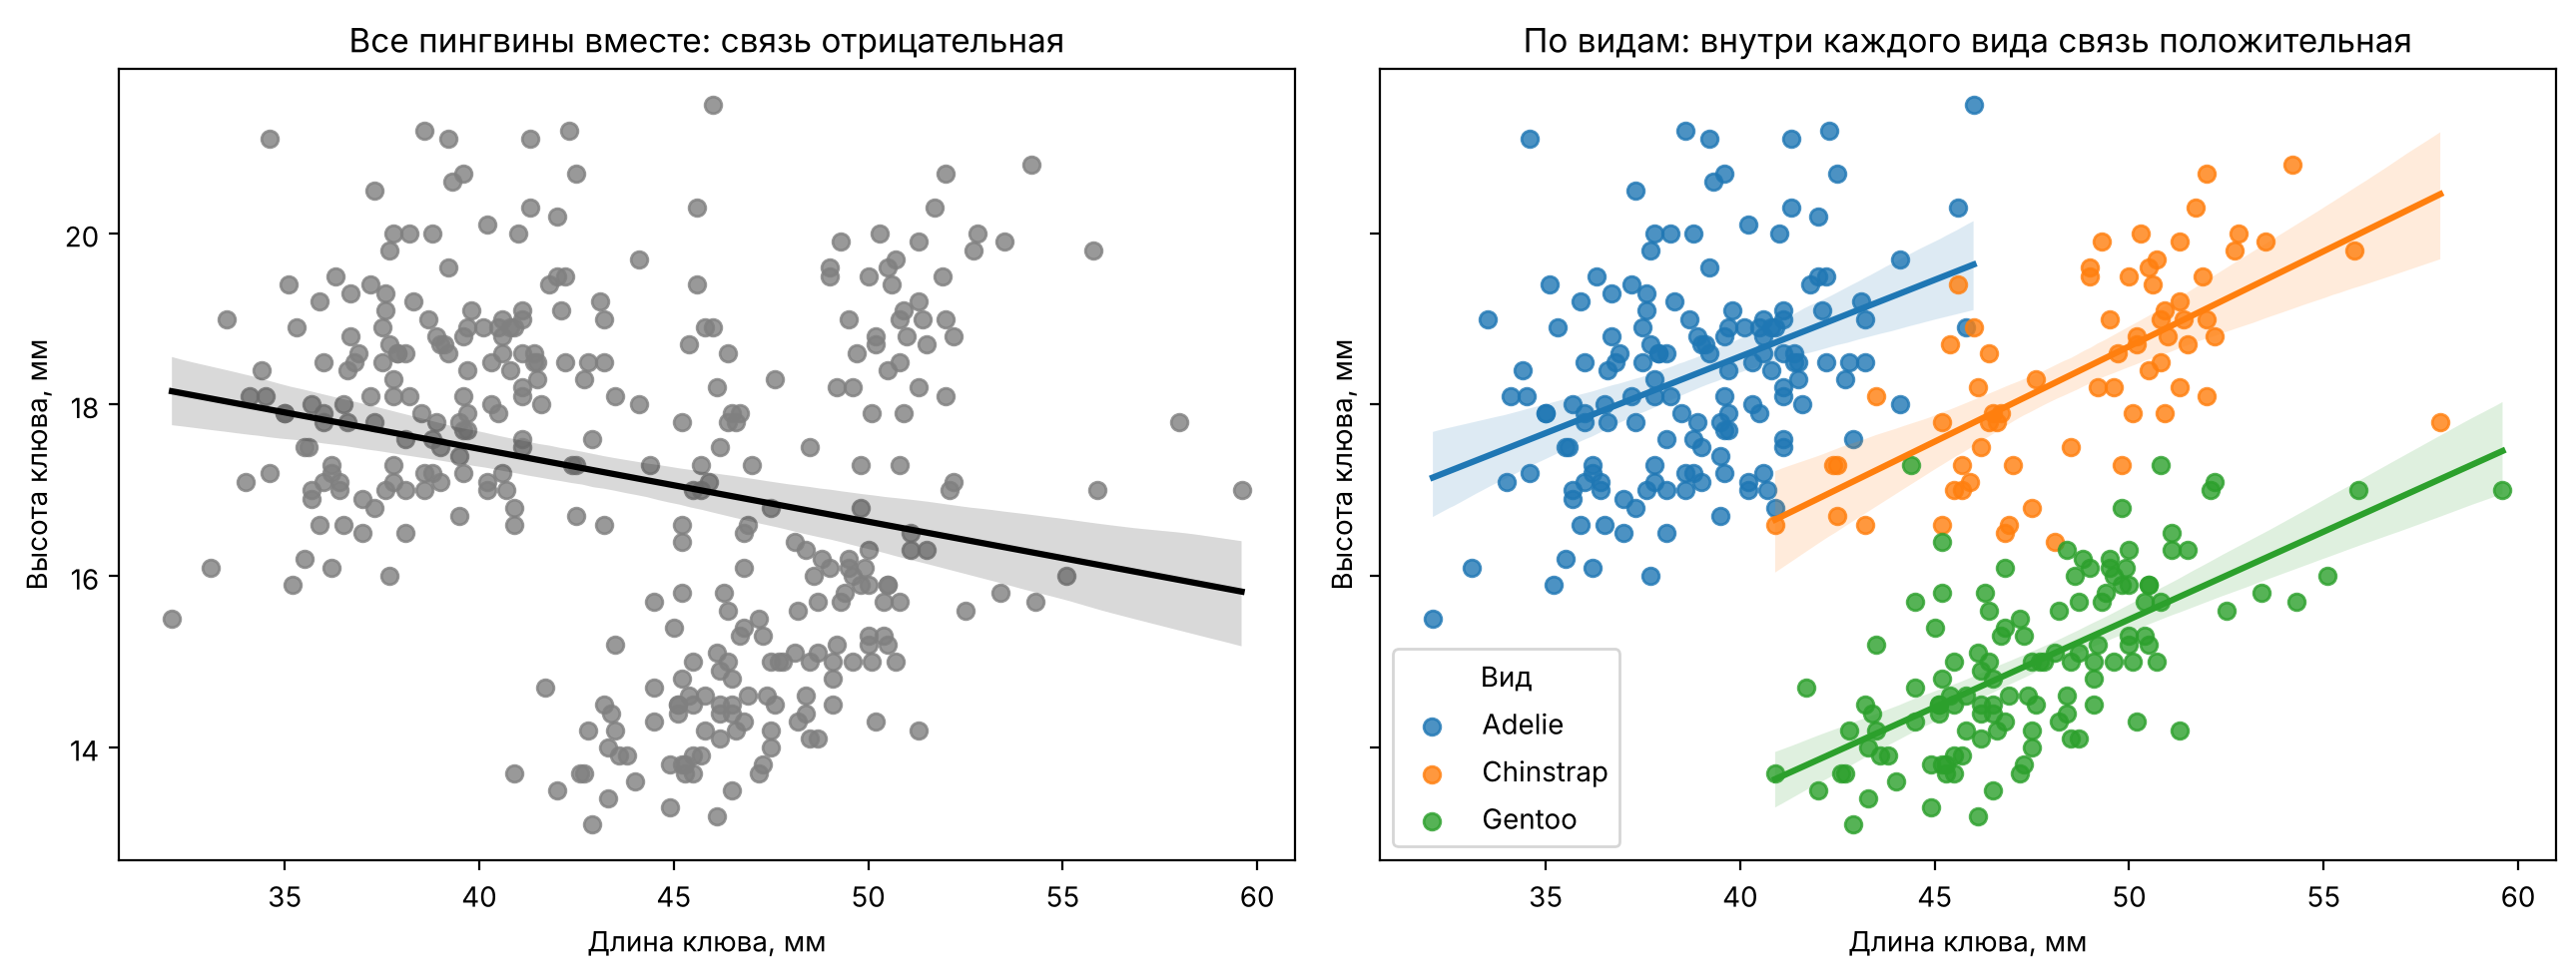

In [3]:
# ===== 2. Графики: одна общая линия против трёх линий по видам =====
palette = {'Adelie': '#1f77b4', 'Chinstrap': '#ff7f0e', 'Gentoo': '#2ca02c'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

sns.regplot(data=df, x='bill_length_mm', y='bill_depth_mm', ax=axes[0],
            color='grey', line_kws={'color': 'black'})
axes[0].set_title('Все пингвины вместе: связь отрицательная')

for sp, g in df.groupby('species'):
    sns.regplot(data=g, x='bill_length_mm', y='bill_depth_mm', ax=axes[1],
                color=palette[sp], label=sp)
axes[1].set_title('По видам: внутри каждого вида связь положительная')
axes[1].legend(title='Вид')

for ax in axes:
    ax.set_xlabel('Длина клюва, мм')
    ax.set_ylabel('Высота клюва, мм')
plt.tight_layout()
plt.show()